In [1]:
import torch
import os

os.environ["GEOMSTATS_BACKEND"] = "pytorch"
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA


[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
from sklearn import datasets
iris = datasets.load_iris()

In [3]:
X = iris.data

In [4]:
X.shape

(150, 4)

In [5]:
## PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

In [6]:
X_reduced.shape

(150, 2)

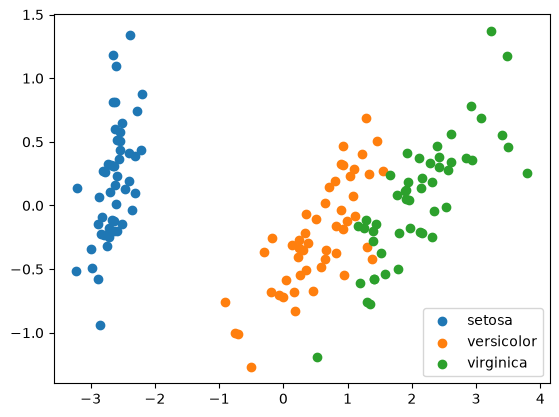

In [7]:
for k in range(3):
    plt.scatter(X_reduced[iris.target==k, 0], X_reduced[iris.target==k, 1], label=iris.target_names[k])

plt.legend()
plt.show()

In [8]:
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples_iris)
eigenvectors_distributional = pca_distributional.components_# .numpy()

# print("Barycenter cost:", lifted_pca.cost_barycenter(samples_iris))

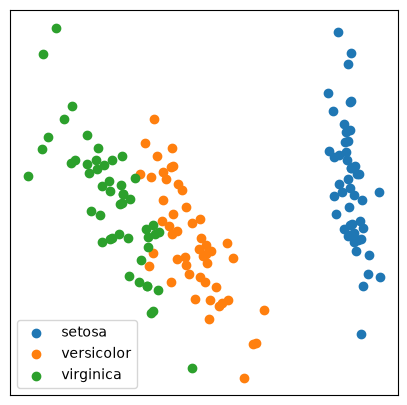

In [9]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", pca_distributional.components_, torch.from_numpy(X)).numpy()
for k in range(3):
    ax.scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

In [10]:
# Fix the support and optim over weights only
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

lifted_pca = LiftedPCA(n_components=2, n_samples=100)
lifted_pca.fit(samples_iris)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples_iris)
eigenvectors_distributional = pca_distributional.components_# .numpy()

print("Barycenter cost:", lifted_pca.cost_barycenter(samples_iris))

INFO:2026-09-29 11:04:02,748:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: tensor(0.0023)


In [11]:
lifted_pca.components_.shape

torch.Size([100, 4, 2])

In [12]:
pca_distributional.components_

tensor([[-0.3621,  0.6571],
        [ 0.0840,  0.7294],
        [-0.8565, -0.1741],
        [-0.3581, -0.0768]])

In [13]:
from matplotlib.lines import Line2D
from lib_pca.utils_plot import plot_gaussian_kde

In [14]:
from scipy.stats import gaussian_kde


def plot_gaussian_kde_v2(samples, bandwidth=0.3, ax=None, color=None, xmin=-3, xmax=3, ymin=-3, ymax=3, label=None):
    """
        Gaussian KDE.

        Parameters
        ----------
        samples: tensor of shape (n, d)
    """
    if ax is None:
        ax = plt.gca()

    x_grid = torch.linspace(xmin, xmax, 100)
    y_grid = torch.linspace(ymin, ymax, 100)
    grid_x, grid_y = torch.meshgrid(x_grid, y_grid, indexing="xy")
    zeros = torch.zeros(len(grid_x.reshape(-1)))
    grid = torch.stack([zeros, grid_x.reshape(-1), grid_y.reshape(-1), zeros])

    kde = gaussian_kde(samples.T, bw_method=bandwidth)
    density = kde(grid.detach().cpu().numpy()).reshape(grid_x.shape)
    levels = density.max() * np.linspace(0.2, 0.9, 5)

    ax.contour(
        grid_x,
        grid_y,
        density,
        levels=levels,
        colors=[color],
        linewidths=1.2,
        alpha=0.9
    )

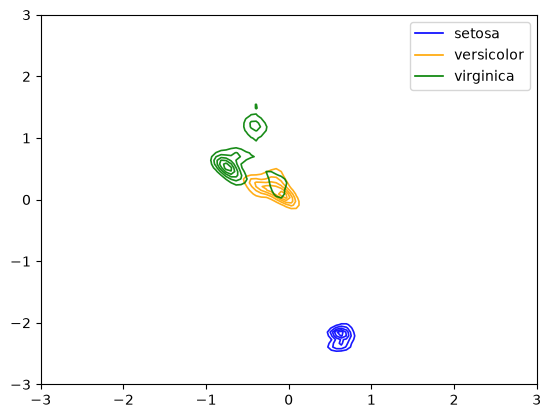

In [15]:
## WRONG

centered_samples = lifted_pca.center_data(samples_iris)

palette = ["blue", "orange", "green"]

legend_handles = []

for k in range(len(centered_samples)):
    plot_gaussian_kde_v2(lifted_pca.project_samples(centered_samples[k]).reshape(-1, 4), color=palette[k])

    legend_handles.append(Line2D([0], [0], color=palette[k], lw=1.2, label=iris.target_names[k]))


plt.legend(handles=legend_handles)


plt.show()

In [16]:
# lifted_pca.project_samples(centered_samples[0]).shape

In [17]:
L_projected_samples = []
for k in range(len(centered_samples)):
    projected_samples = lifted_pca.project_samples(centered_samples[k]).reshape(-1, 4)
    L_projected_samples.append(projected_samples)

In [18]:
full_projected_samples = torch.stack(L_projected_samples).reshape(-1, 4)

In [19]:
pca = PCA(2)
projected_samples_2D = pca.fit_transform(full_projected_samples)

In [20]:
projected_samples_2D.shape

torch.Size([15000, 2])

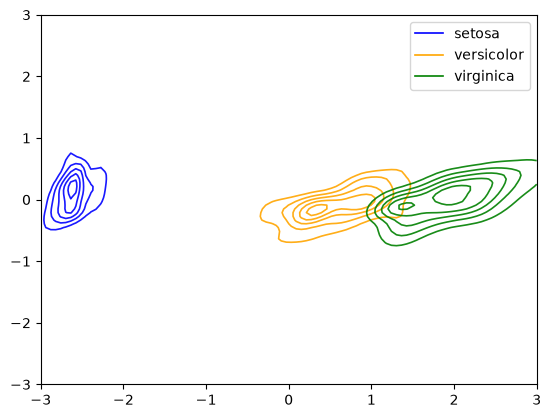

In [21]:
centered_samples = lifted_pca.center_data(samples_iris)

palette = ["blue", "orange", "green"]

legend_handles = []

for k in range(len(centered_samples)):
    plot_gaussian_kde(projected_samples_2D[k*5000: (k+1)*5000], color=palette[k])

    legend_handles.append(Line2D([0], [0], color=palette[k], lw=1.2, label=iris.target_names[k]))


plt.legend(handles=legend_handles)


plt.show()

In [22]:
U_bary = lifted_pca.get_barycenter_components()

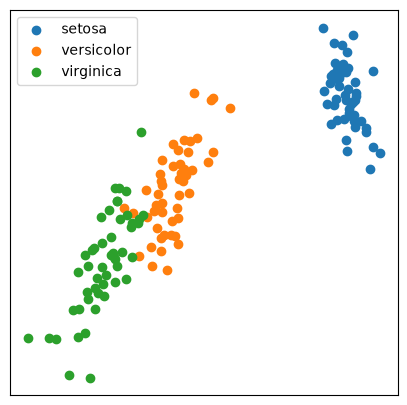

In [23]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", U_bary, torch.from_numpy(X)).numpy()
for k in range(3):
    ax.scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

In [24]:
from geomstats.geometry.grassmannian import Grassmannian
from geomstats.learning.pca import TangentPCA



grassmann = Grassmannian(lifted_pca.components_.shape[1], lifted_pca.n_components)
tpca = TangentPCA(grassmann, n_components=2)

projectors = torch.einsum("idq,ieq->ide", lifted_pca.components_, lifted_pca.components_)
barycenter = lifted_pca.get_barycenter_components()
barycenter_grassmann = barycenter @ barycenter.T

tpca.fit(projectors, base_point=barycenter_grassmann)
tangent_projected_data = tpca.transform(projectors)

pairwise_distances = torch.stack([
    torch.stack([
        grassmann.metric.dist(projectors[i], projectors[j])
        for j in range(projectors.shape[0])
    ])
    for i in range(projectors.shape[0])
])

upper_triangle = torch.triu_indices(
    row=pairwise_distances.shape[0],
    col=pairwise_distances.shape[1],
    offset=1,
)
median_pairwise_distance = torch.median(
    pairwise_distances[upper_triangle[0], upper_triangle[1]]
)

print("Median pairwise Grassmann distance:", median_pairwise_distance.item())

Median pairwise Grassmann distance: 1.2546615196667772


In [25]:
from lib_pca.utils_kde import projection_metric, kde_stiefel


# weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, median_pairwise_distance.item()/2).numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 1).numpy()

min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

In [26]:
# from geomstats.learning.kernel_density_estimation_classifier import KernelDensityEstimationClassifier

# kde = KernelDensityEstimationClassifier(grassmann)
# kde.fit(projectors)

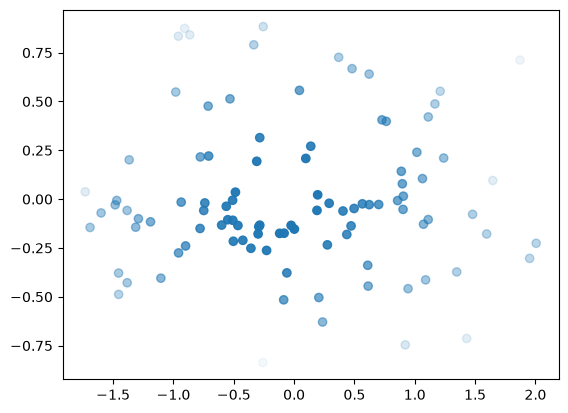

In [27]:
plt.scatter(tangent_projected_data[:,0], tangent_projected_data[:,1], alpha=alpha)
plt.show()

In [28]:
weights.min()

np.float64(0.014062663348776958)

In [29]:
weights.max()

np.float64(0.01880978009831957)

In [30]:
from lib_pca.mean_shift import grassmann_mean_shift, cluster_grassmann_points

In [31]:
Q = grassmann_mean_shift(lifted_pca.components_, 1)

In [32]:
labels, mode = cluster_grassmann_points(Q, 1)
np.unique(labels)

array([0])

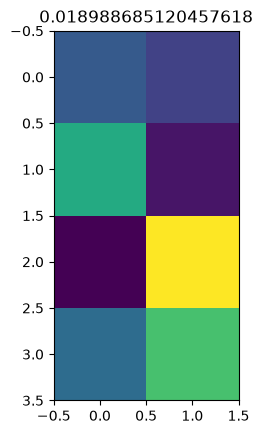

In [33]:
for k in range(len(mode)):
    plt.imshow(mode[k])
    plt.title(str(kde_stiefel(mode[k][None], lifted_pca.components_, 1).item()))
    plt.show()

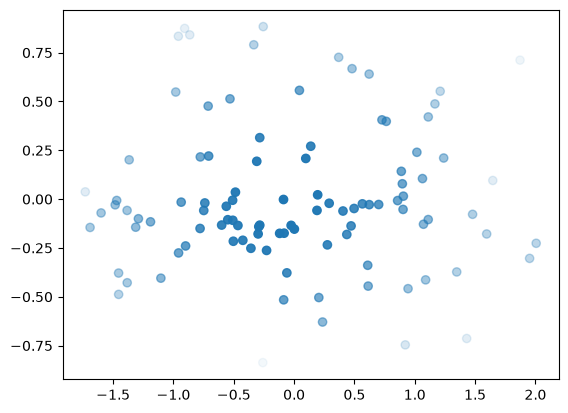

In [34]:
project_modes = tpca.transform(torch.einsum("idq,ieq->ide", mode, mode))

for k in range(len(labels)):
    plt.scatter(tangent_projected_data[:,0][labels==k], tangent_projected_data[:,1][labels==k], alpha=alpha)
plt.scatter(project_modes[:,0], project_modes[:,1])
plt.show()

In [35]:
torch.einsum("idq,ieq->ide", mode, mode).shape

torch.Size([1, 4, 4])

In [36]:
labels

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0])

In [70]:
bandwidths = torch.logspace(-1, 1, 30)

n_modes = []

for h in bandwidths:
    weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, h).numpy()
    Q = grassmann_mean_shift(lifted_pca.components_, h)

    labels, mode = cluster_grassmann_points(Q, 1)
    n_modes.append(len(mode))


    project_modes = tpca.transform(torch.einsum("idq,ieq->ide", mode, mode))

    # for k in range(len(labels)):
    #     plt.scatter(tangent_projected_data[:,0][labels==k], tangent_projected_data[:,1][labels==k], alpha=alpha)
    # plt.scatter(project_modes[:,0], project_modes[:,1])
    # plt.show()

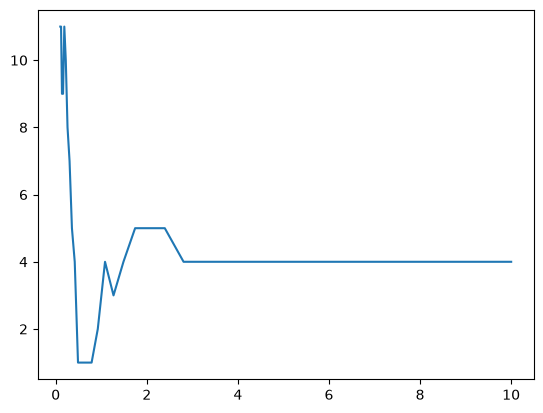

In [71]:
plt.plot(bandwidths, n_modes)
plt.show()

In [78]:
Q = grassmann_mean_shift(lifted_pca.components_, 10, max_iter=1000)
labels, mode = cluster_grassmann_points(Q,10)
len(mode)

1

In [21]:
lifted_pca.components_.shape

torch.Size([10, 4, 2])

In [22]:
Z = torch.randn(100, 4, 2)
U, _ = torch.linalg.qr(Z)

In [23]:
kde_stiefel(U, lifted_pca.components_, 0.25)

tensor([0.0363, 0.0059, 0.0047, 0.0104, 0.0028, 0.1037, 0.2765, 0.1085, 0.0302,
        0.0140, 0.1036, 0.0149, 0.0158, 0.0697, 0.0414, 0.0086, 0.0217, 0.0045,
        0.0068, 0.1356, 0.0606, 0.3003, 0.0077, 0.0031, 0.0038, 0.1773, 0.0960,
        0.0665, 0.0210, 0.0129, 0.2792, 0.0183, 0.0111, 0.0180, 0.0082, 0.0520,
        0.0651, 0.3882, 0.0998, 0.0082, 0.1631, 0.2458, 0.1072, 0.4188, 0.0384,
        0.0322, 0.0839, 0.0676, 0.0474, 0.0023, 0.1665, 0.4135, 0.0125, 0.0155,
        0.0350, 0.0189, 0.0036, 0.0409, 0.0449, 0.1403, 0.0104, 0.2700, 0.0016,
        0.0490, 0.0792, 0.1064, 0.0346, 0.0189, 0.0375, 0.1699, 0.0138, 0.0581,
        0.0137, 0.0148, 0.0018, 0.0159, 0.0086, 0.0028, 0.0735, 0.0898, 0.0403,
        0.0206, 0.0073, 0.2627, 0.0523, 0.0290, 0.0016, 0.4668, 0.0034, 0.0943,
        0.0675, 0.0627, 0.0034, 0.0904, 0.1063, 0.0098, 0.0025, 0.0025, 0.0244,
        0.0118])

In [24]:
print(kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).min(), kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).max())

tensor(0.6539) tensor(0.8881)


In [25]:
kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25)

tensor([0.6539, 0.7092, 0.6721, 0.6894, 0.8551, 0.8881, 0.7286, 0.6551, 0.6904,
        0.6887])

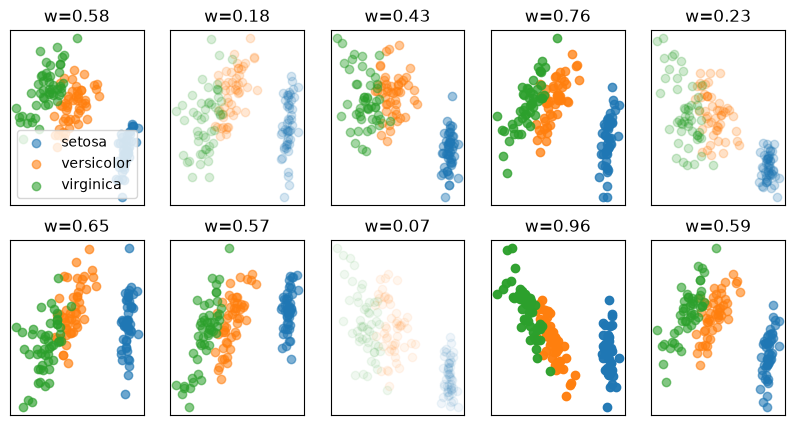

In [37]:
# weights = lifted_pca.weights_.numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=2, 
    ncols=5,
    figsize=(10,5)
)

for i in range(2):
    for j in range(5):
        U = lifted_pca.components_[i*5+j]
        proj_points = torch.einsum("ij, ki -> kj", U, torch.from_numpy(X)).numpy()
        for k in range(3):
            axes[i, j].scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k] , alpha=alpha[i*5+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        axes[i, j].set_title("w=" + str(round(alpha[i*5+j], 2)))

plt.show()

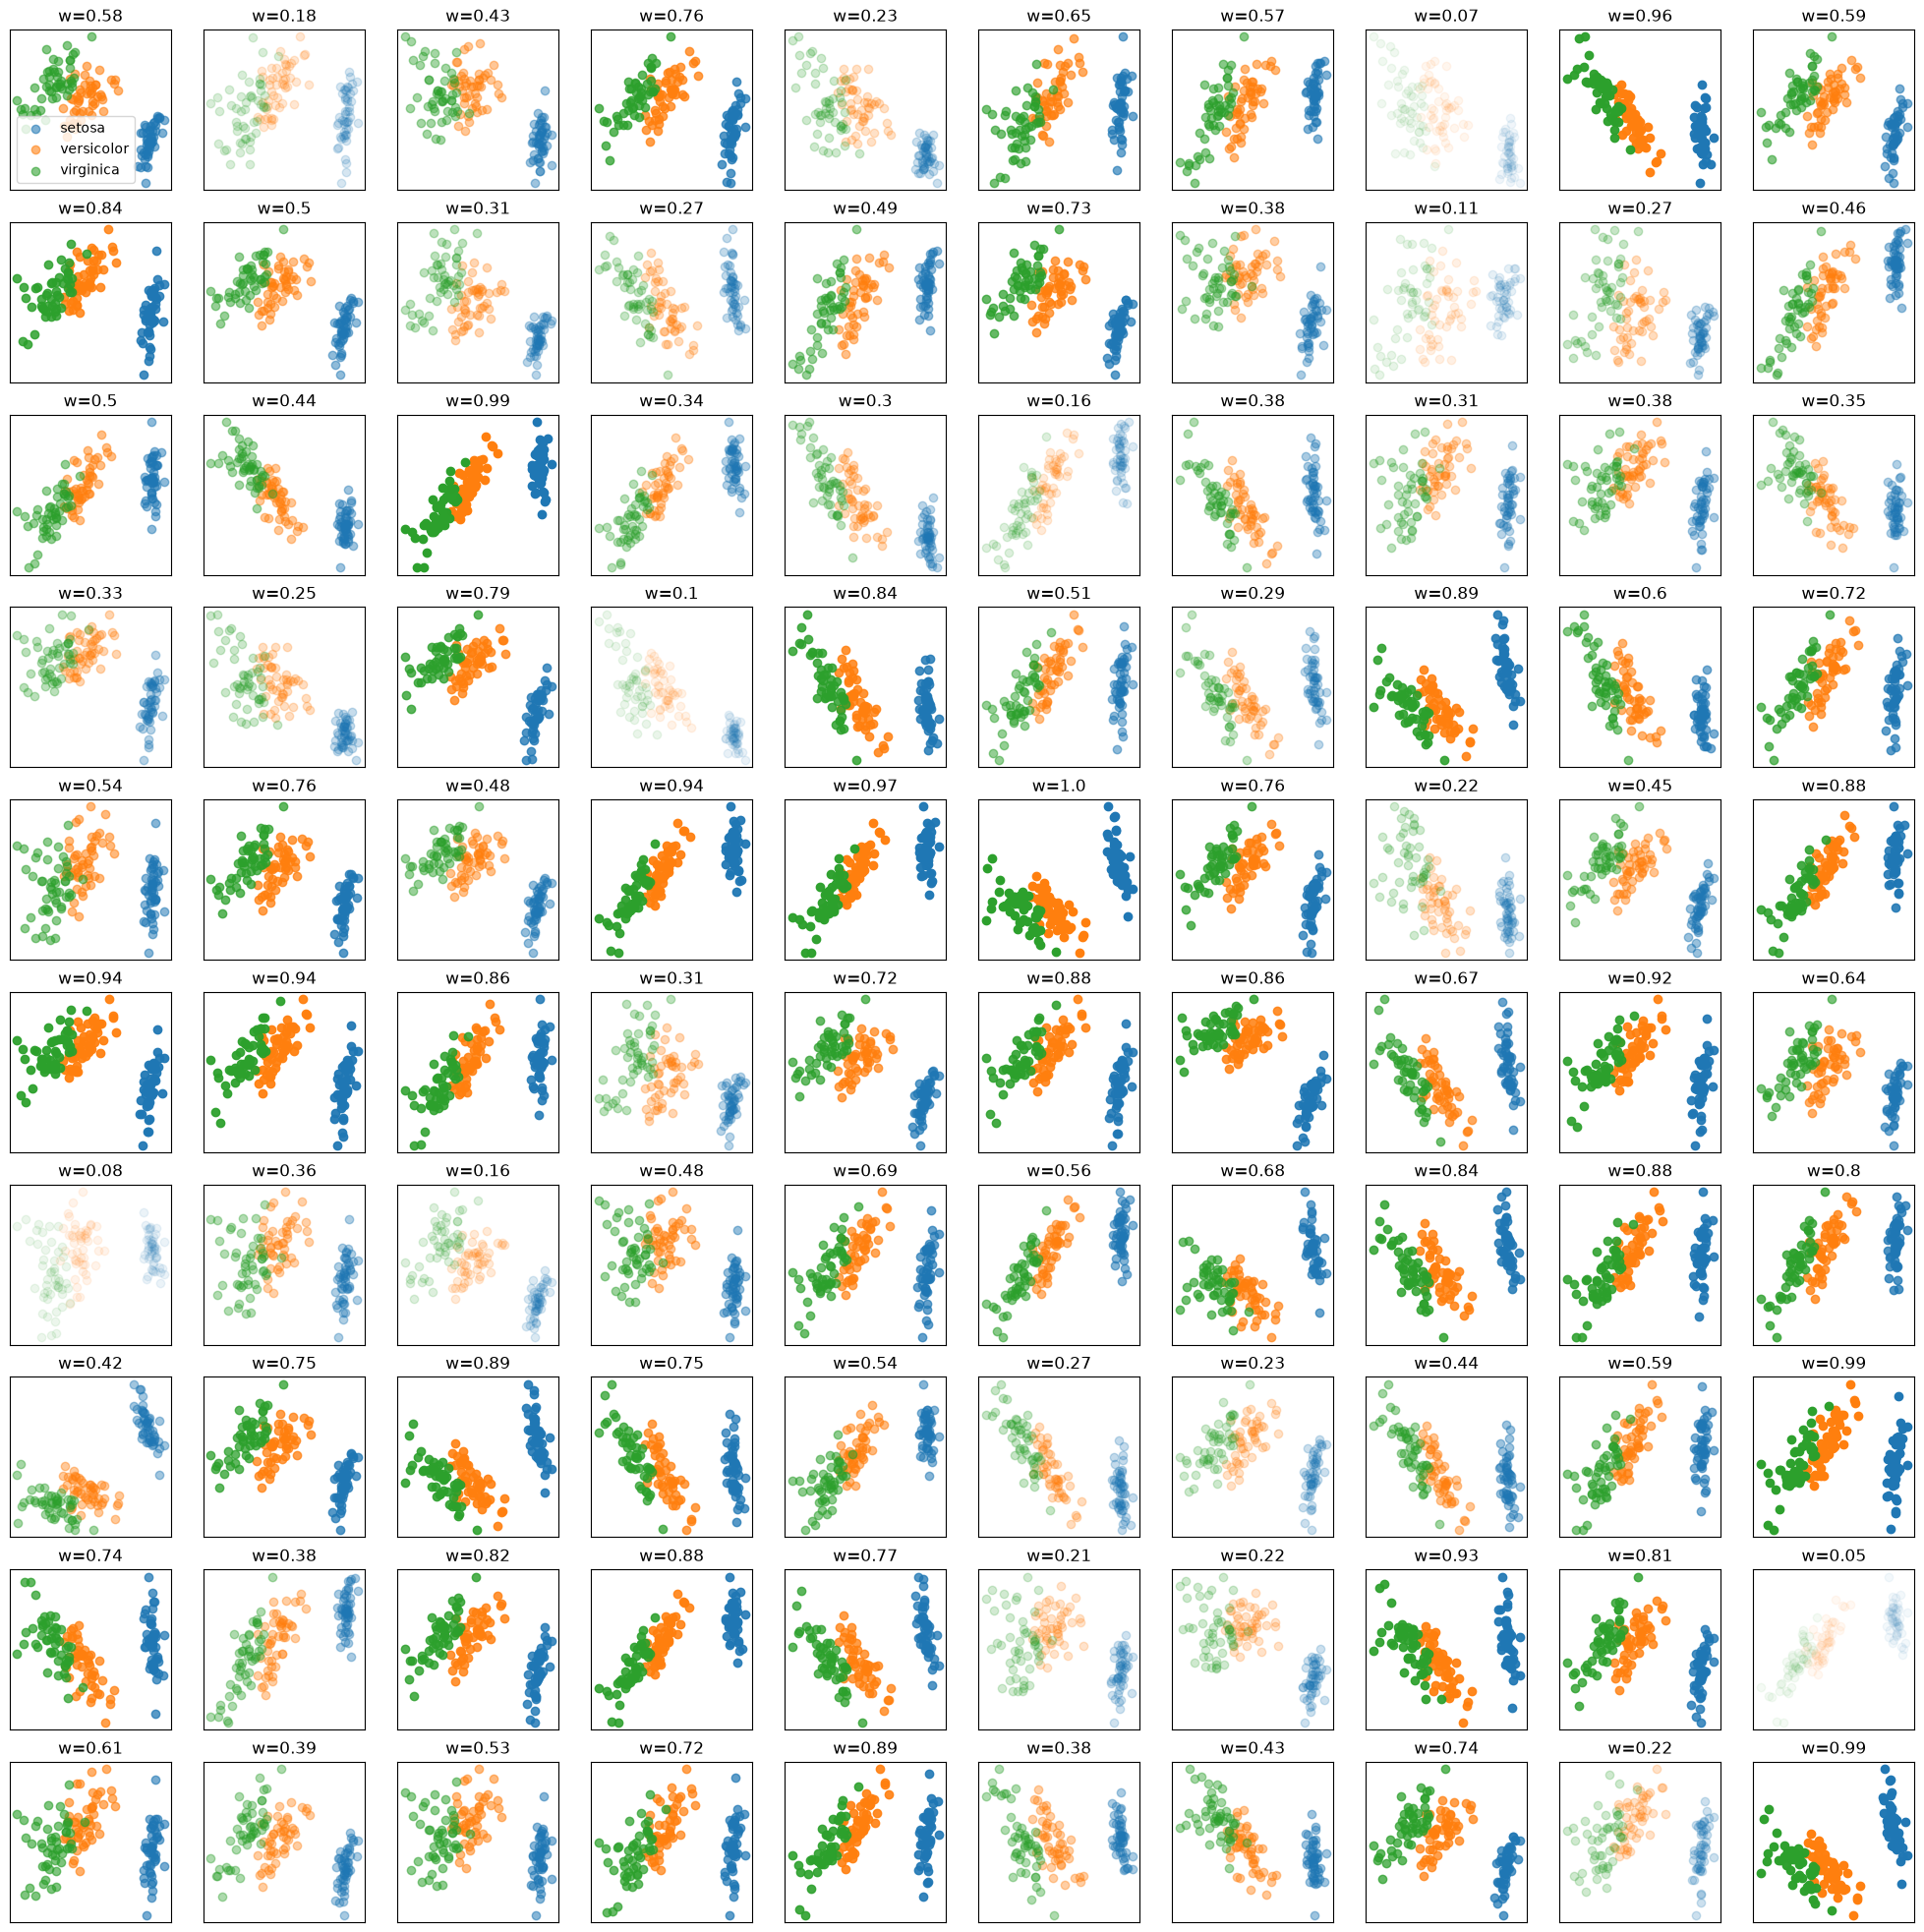

In [38]:
# weights = lifted_pca.weights_.numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, torch.from_numpy(X)).numpy()
        for k in range(3):
            axes[i, j].scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k] , alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        axes[i, j].set_title("w=" + str(round(alpha[i*10+j], 2)))

plt.show()

In [39]:
distr_projs = torch.einsum("ndq, npq -> ndp", lifted_pca.components_, lifted_pca.components_)

In [40]:
torch.mean(distr_projs, axis=0)

tensor([[ 0.4870,  0.1121,  0.1791,  0.0275],
        [ 0.1121,  0.4328, -0.1401,  0.0573],
        [ 0.1791, -0.1401,  0.7746,  0.2952],
        [ 0.0275,  0.0573,  0.2952,  0.3056]])

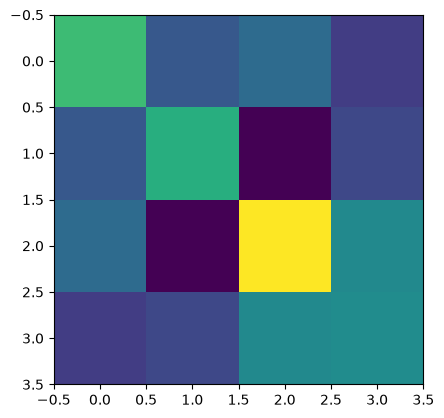

In [41]:
plt.imshow(torch.mean(distr_projs, axis=0))

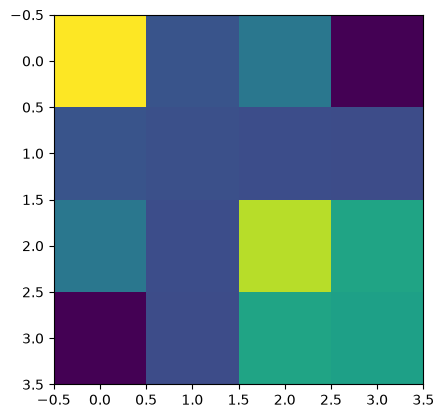

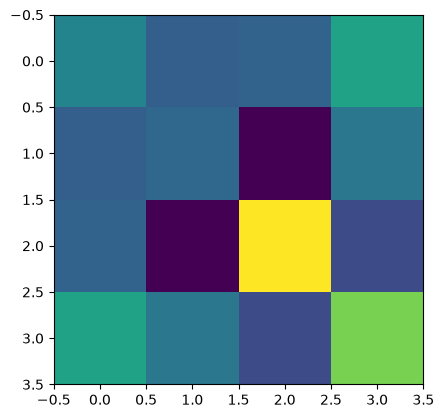

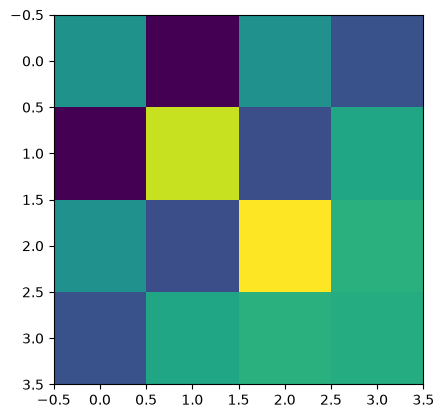

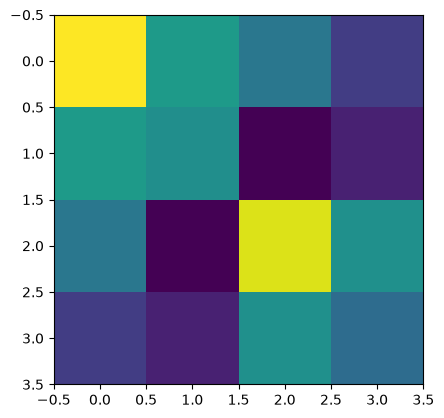

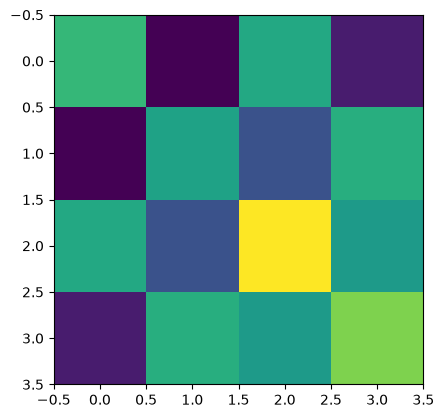

In [42]:
for k in range(5):
    plt.imshow(distr_projs[k])
    plt.show()

In [43]:
def grassmann_distance(U: torch.Tensor,
                       V: torch.Tensor,
                       eps: float = 1e-7) -> torch.Tensor:
    """
    Geodesic distance on the Grassmann manifold Gr(p, k).

    U: (n, k, p) orthonormal basis matrices
    V: (m, k, p) orthonormal basis matrices

    Returns:
        (n, m) Grassmann distances.

    Leading dimensions are broadcastable.
    """
    # (..., p, p)
    M = U.transpose(-2, -1)[:, None] @ V[None, :]

    # Principal-angle cosines = singular values
    s = torch.linalg.svdvals(M)

    # Numerical safety for acos
    s = s.clamp(0.0, 1.0)

    theta = torch.acos(s)

    return torch.linalg.vector_norm(theta, dim=-1)

In [ ]:
pairwise_dist = grassmann_distance(lifted_pca.components_, lifted_pca.components_)

In [ ]:
pairwise_dist.shape

torch.Size([500, 500])

In [ ]:
from sklearn.manifold import MDS


In [ ]:
mds = MDS(2, metric="precomputed")
emb = mds.fit_transform(pairwise_dist.numpy())


/home/clement/envs_python/py312/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


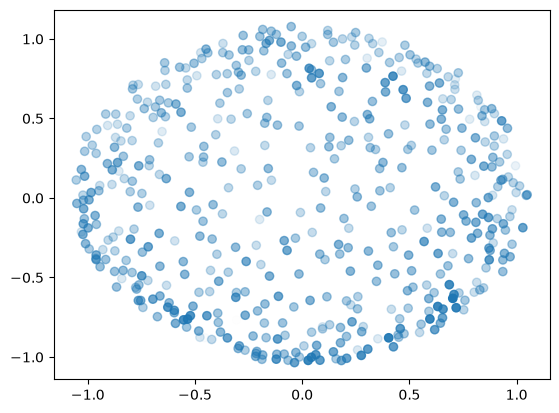

In [ ]:
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = (weights - min_weights) / diff

plt.scatter(emb[:,0], emb[:,1], alpha=alpha)

In [ ]:
min_weights

np.float64(0.04041080662113962)

In [ ]:
max_weights

np.float64(0.11565745488530621)

In [ ]:
alpha.max()

np.float64(1.0)

In [ ]:
lifted_pca.components_

torch.Size([500, 4, 2])

In [ ]:
import torch


def plucker_matrix(U):
    """
    U: (n, d, 2)

    Returns:
        A: (n, d, d)

    where
        A[:, i, j] = det(U[:, [i,j], :])^2
    for i != j, and
        A[:, i, i] = 0.
    """
    n, d, q = U.shape
    assert q == 2

    pairs = torch.combinations(
        torch.arange(d, device=U.device),
        r=2
    )

    i = pairs[:, 0]
    j = pairs[:, 1]

    # (n, num_pairs, 2)
    ui = U[:, i, :]
    uj = U[:, j, :]

    # 2x2 determinants
    P = ui[..., 0] * uj[..., 1] - ui[..., 1] * uj[..., 0]

    # Squared Plücker coordinates
    P2 = P.square()

    # Put into symmetric matrix
    A = torch.zeros(
        n, d, d,
        dtype=U.dtype,
        device=U.device
    )

    A[:, i, j] = P2
    A[:, j, i] = P2

    return A

In [ ]:
coords = plucker_matrix(lifted_pca.components_)

In [ ]:
coords.shape

torch.Size([500, 4, 4])

In [ ]:
coords[0]

tensor([[0.0000, 0.1902, 0.0161, 0.1081],
        [0.1902, 0.0000, 0.1068, 0.5782],
        [0.0161, 0.1068, 0.0000, 0.0006],
        [0.1081, 0.5782, 0.0006, 0.0000]])

In [ ]:
torch.mean(coords, axis=0)

tensor([[0.0000, 0.1786, 0.1736, 0.1535],
        [0.1786, 0.0000, 0.1638, 0.1616],
        [0.1736, 0.1638, 0.0000, 0.1688],
        [0.1535, 0.1616, 0.1688, 0.0000]])

In [ ]:
coords[np.argmax(weights)]

tensor([[0.0000, 0.0900, 0.2217, 0.0245],
        [0.0900, 0.0000, 0.0625, 0.1266],
        [0.2217, 0.0625, 0.0000, 0.4748],
        [0.0245, 0.1266, 0.4748, 0.0000]])

In [ ]:
print(weights[0], weights.max())

0.062059033940918856 0.11565745488530621


np.int64(285)

In [ ]:
A = torch.zeros((4,4))

for i in range(4):
    for j in range(4):
        sub_matrix = lifted_pca.components_[0][np.ix_([i,j],[0,1])]
        A[i,j] = torch.linalg.det(sub_matrix)**2        

In [ ]:
A

tensor([[1.9945e-35, 1.9022e-01, 1.6063e-02, 1.0812e-01],
        [1.9022e-01, 3.4323e-37, 1.0677e-01, 5.7818e-01],
        [1.6063e-02, 1.0677e-01, 1.4428e-37, 6.4452e-04],
        [1.0812e-01, 5.7818e-01, 6.4452e-04, 3.8436e-35]])

In [ ]:
torch.sum(A)

tensor(2.0000)

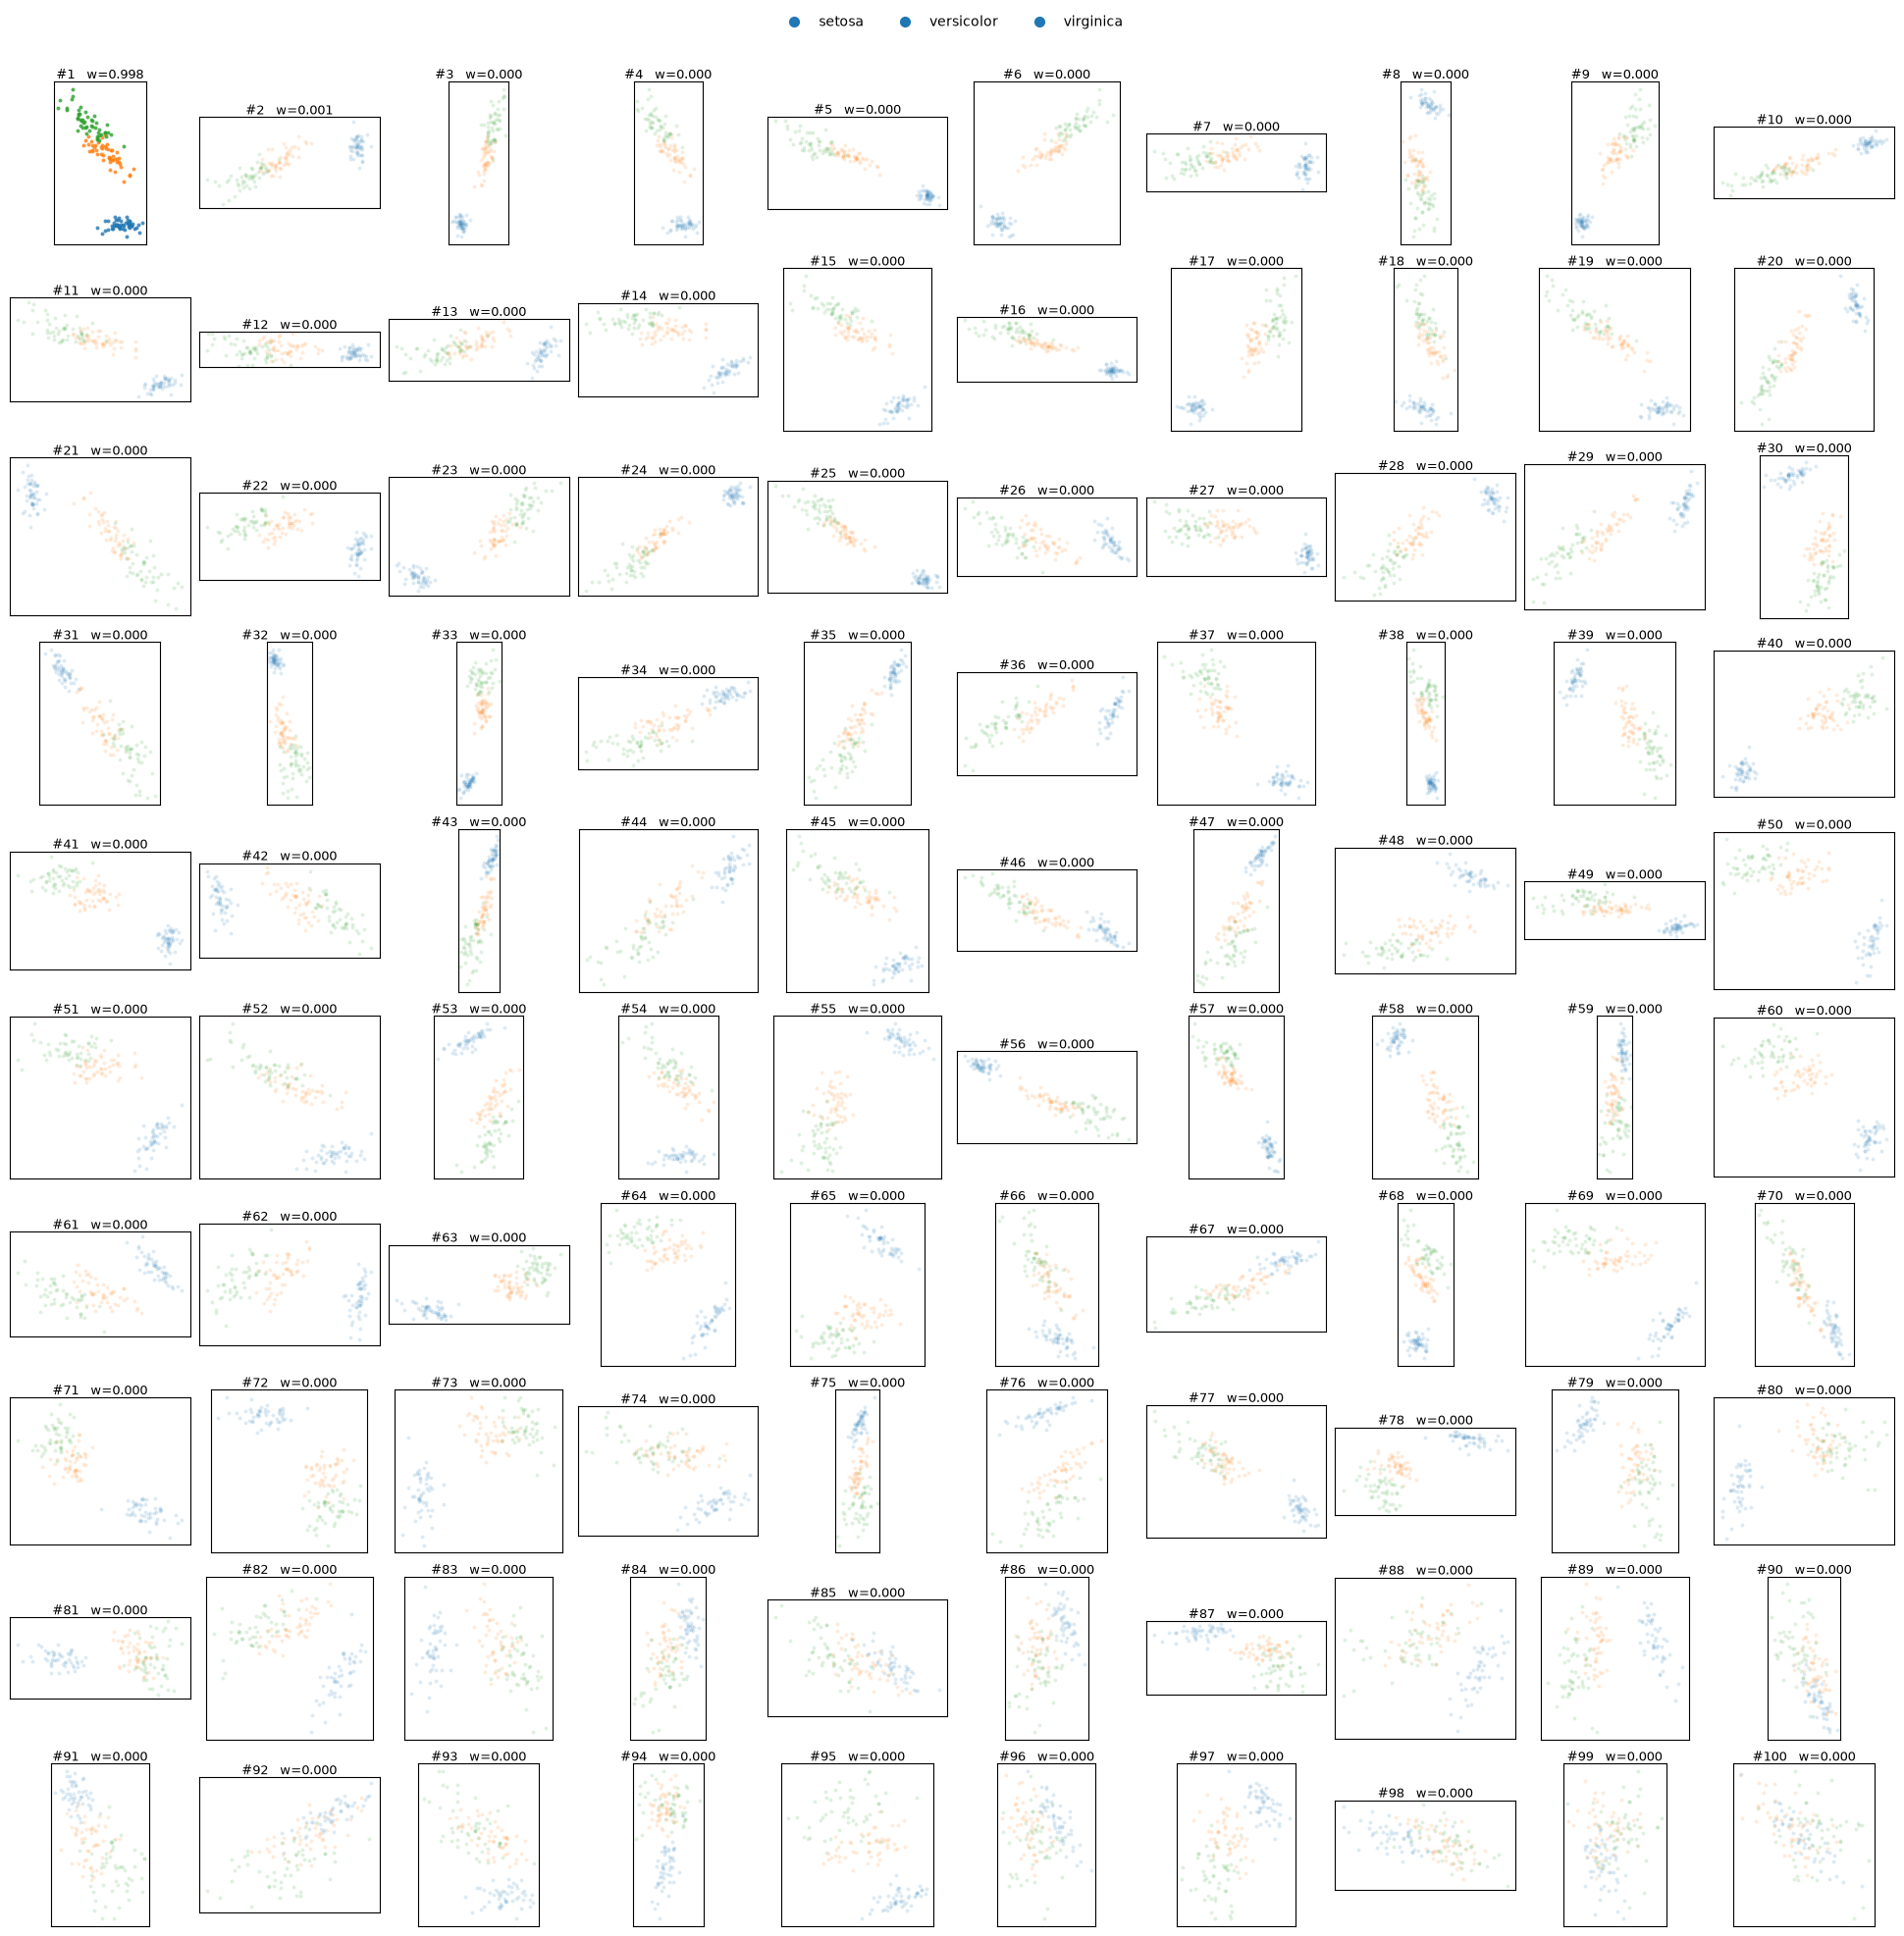

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
weights = lifted_pca.weights_.detach().cpu().numpy()

# Sort planes by decreasing weight
order = np.argsort(weights)[::-1]

weights_sorted = weights[order]

# Robust normalization of weights
w = (weights_sorted - weights_sorted.min()) / (
    weights_sorted.max() - weights_sorted.min() + 1e-12
)

# Alpha for points: don't make low-weight planes completely disappear
point_alpha = 0.15 + 0.65 * w


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(20, 20),
)

X_torch = torch.from_numpy(X)

for plot_idx, plane_idx in enumerate(order):

    i, j = divmod(plot_idx, 10)

    ax = axes[i, j]

    # --------------------------------------------------------
    # Project data onto this 2D plane
    # U: (4, 2)
    # X: (N, 4)
    # --------------------------------------------------------
    U = lifted_pca.components_[plane_idx]

    if isinstance(U, torch.Tensor):
        U = U.detach().cpu()

    proj_points = X_torch @ U
    proj_points = proj_points.numpy()

    # --------------------------------------------------------
    # Plot the three classes
    # --------------------------------------------------------
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=8,
            alpha=point_alpha[plot_idx],
            linewidths=0,
            label=iris.target_names[k],
        )

    # --------------------------------------------------------
    # Plane information
    # --------------------------------------------------------
    ax.set_title(
        f"#{plot_idx + 1}   w={weights[plane_idx]:.3f}",
        fontsize=9,
        pad=2,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Equal aspect ratio is important:
    # otherwise the geometry of the projected plane is distorted.
    ax.set_aspect("equal", adjustable="box")


# ------------------------------------------------------------
# One global legend
# ------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=7,
        label=iris.target_names[k],
    )
    for k in range(3)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.02,
    top=0.96,
    wspace=0.05,
    hspace=0.15,
)

plt.show()

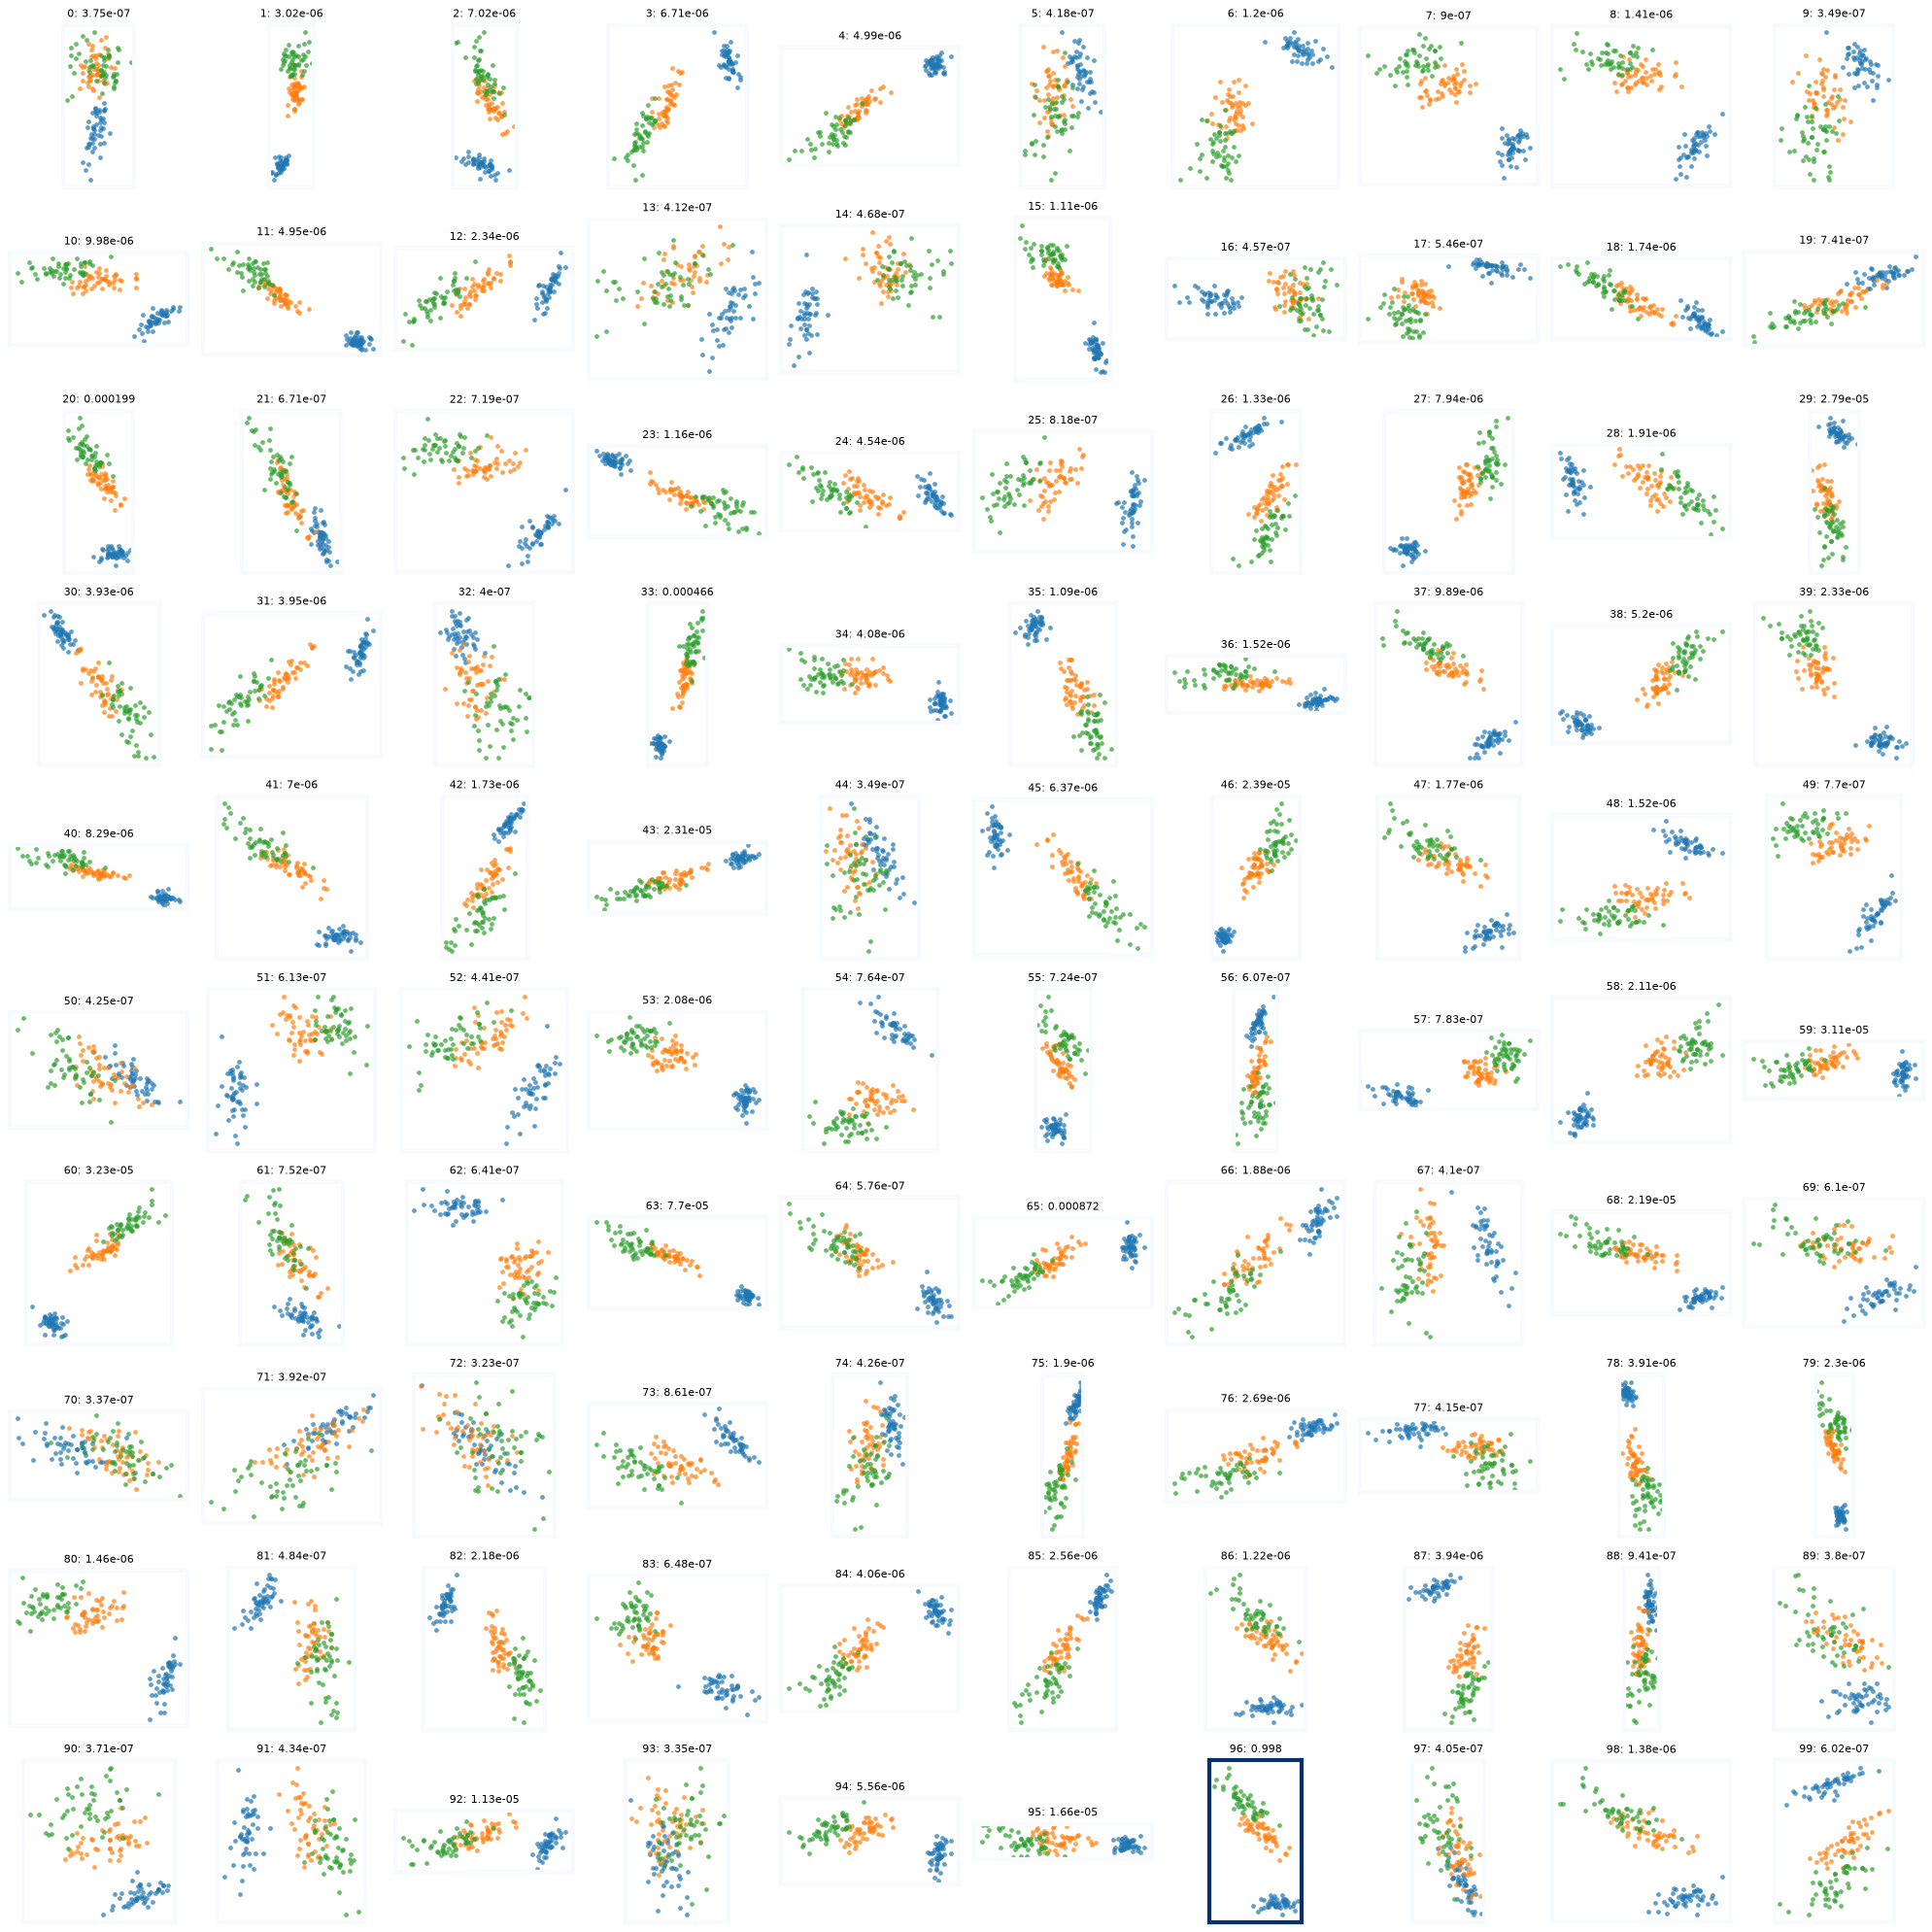

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import colormaps

weights = lifted_pca.weights_.detach().cpu().numpy()

# Normalize weights
w = (weights - weights.min()) / (
    weights.max() - weights.min() + 1e-12
)

cmap = colormaps["Blues"]

fig, axes = plt.subplots(
    10, 10,
    figsize=(20, 20),
)

for idx, ax in enumerate(axes.flat):

    # Your original plane
    U = lifted_pca.components_[idx]

    # Your original projection -- DO NOT CHANGE THIS
    proj_points = torch.einsum(
        "ij,ki->kj",
        U,
        torch.from_numpy(X)
    ).numpy()

    # Plot classes
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=12,
            alpha=0.7,
            linewidths=0,
        )

    # Weight represented by the border
    color = cmap(w[idx])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(3)
        spine.set_color(color)

    ax.set_title(
        f"{idx}: {weights[idx]:.3g}",
        fontsize=8,
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [ ]:
# Z = pca_distributional.components_
Z = lifted_pca.components_[np.argmax(lifted_pca.weights_)]

In [ ]:
Z.T @ Z

tensor([[1.0000, 0.0000],
        [0.0000, 1.0000]], dtype=torch.float64)

In [ ]:
lifted_pca.components_[np.argmax(lifted_pca.weights_)].shape

torch.Size([4, 2])

In [ ]:
from lib_pca.stiefel_kde import StiefelGrassmannKDE

# KDE on the Grassmann quotient represented by the Stiefel components.
stiefel_kde = StiefelGrassmannKDE(bandwidth=0.25).fit(lifted_pca.components_)
density = stiefel_kde.score_samples(lifted_pca.components_)

print("Density shape:", density.shape)
print("Density range:", density.min().item(), density.max().item())

Density shape: torch.Size([500])
Density range: 0.006057850078205451 0.01719727474677588


In [ ]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

In [ ]:
stiefel_kde.score_samples(U)


tensor([0.0066, 0.0084, 0.0108, 0.0056, 0.0075, 0.0086, 0.0105, 0.0098, 0.0091,
        0.0094, 0.0073, 0.0101, 0.0088, 0.0078, 0.0075, 0.0101, 0.0111, 0.0101,
        0.0052, 0.0087, 0.0128, 0.0095, 0.0099, 0.0107, 0.0102, 0.0075, 0.0083,
        0.0073, 0.0095, 0.0076, 0.0078, 0.0134, 0.0086, 0.0087, 0.0096, 0.0043,
        0.0069, 0.0104, 0.0095, 0.0039, 0.0077, 0.0112, 0.0105, 0.0064, 0.0054,
        0.0092, 0.0086, 0.0138, 0.0140, 0.0073, 0.0081, 0.0104, 0.0087, 0.0073,
        0.0096, 0.0121, 0.0061, 0.0089, 0.0111, 0.0105, 0.0104, 0.0118, 0.0076,
        0.0073, 0.0088, 0.0100, 0.0108, 0.0076, 0.0098, 0.0125, 0.0090, 0.0077,
        0.0103, 0.0087, 0.0088, 0.0075, 0.0115, 0.0118, 0.0095, 0.0084, 0.0128,
        0.0102, 0.0080, 0.0097, 0.0059, 0.0075, 0.0077, 0.0097, 0.0084, 0.0084,
        0.0096, 0.0104, 0.0108, 0.0062, 0.0088, 0.0078, 0.0100, 0.0084, 0.0153,
        0.0107])